# Necessary Packages

In [62]:
import pandas as pd
import matplotlib.pyplot as plt
import datetime as dt
import seaborn as sns
import folium
from folium.plugins import HeatMap

# Set a clean visual style for the charts
sns.set_theme(style="whitegrid", palette="muted")

# Dataset

## Dataset Import & Overview

In [16]:
'''ds_names = ['customers', 'order_items', 'order_payments', 'olist_orders', 'products', 'product_translation']
ds_dict = {}

path = Path('/kaggle/input/datasets/olistbr/brazilian-ecommerce')
csv_files = sorted(path.glob('*.csv'))

for acronym, file_path in zip(ds_names, csv_files):
    ds_dict[acronym] = pd.read_csv(file_path)
    print(f"Assigned {file_path.name} to acronym '{acronym}' \n")
    print(f" Df Sample: \n {ds_dict[acronym].sample(5)} \n")
    print(f" Df Info: \n")
    ds_dict[acronym].info() 
    print("\n")
    print(f"Duplicate Rows in {acronym} ds: {ds_dict[acronym].duplicated().sum()}")
    print("\n\n")'''

'ds_names = [\'customers\', \'order_items\', \'order_payments\', \'olist_orders\', \'products\', \'product_translation\']\nds_dict = {}\n\npath = Path(\'/kaggle/input/datasets/olistbr/brazilian-ecommerce\')\ncsv_files = sorted(path.glob(\'*.csv\'))\n\nfor acronym, file_path in zip(ds_names, csv_files):\n    ds_dict[acronym] = pd.read_csv(file_path)\n    print(f"Assigned {file_path.name} to acronym \'{acronym}\' \n")\n    print(f" Df Sample: \n {ds_dict[acronym].sample(5)} \n")\n    print(f" Df Info: \n")\n    ds_dict[acronym].info() \n    print("\n")\n    print(f"Duplicate Rows in {acronym} ds: {ds_dict[acronym].duplicated().sum()}")\n    print("\n\n")'

In [17]:
customers = pd.read_csv("/kaggle/input/datasets/olistbr/brazilian-ecommerce/olist_customers_dataset.csv")
print(f" Customer Df Sample: \n {customers.sample(5)} \n")
print(f" Df Info: \n")
customers.info() 
print("\n")
print(f"Duplicate Rows in ds: {customers.duplicated().sum()}")
print("\n\n")

 Customer Df Sample: 
                             customer_id                customer_unique_id  \
67925  41e8d9c16fbf082197a4584299fc7c03  f8e300d731672bb9dd90d4e85000d8fe   
49244  47aa605e32d7c5f1b6c37de4a646f20a  adcd4db76139274c3d9e3d84f550c1e6   
63223  581472f70857cdfa529a6a282f9e56fd  510c0b04c0a1d626ec12a7bc05852be2   
70189  0cf6581eab07e09cb466aed8cd26107e  77d9cb30f296c026560aa40dca3b2ea2   
39793  4db197e249f43396789685f78b90a530  884deb2952acda1860b0a9f46b6379c1   

       customer_zip_code_prefix customer_city customer_state  
67925                      3186     sao paulo             SP  
49244                      3355     sao paulo             SP  
63223                     15440  nova granada             SP  
70189                     17523       marilia             SP  
39793                     68600      braganca             PA   

 Df Info: 

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 5 columns):
 #   Column   

In [18]:
order_items = pd.read_csv("/kaggle/input/datasets/olistbr/brazilian-ecommerce/olist_order_items_dataset.csv")
print(f" Order Items Df Sample: \n {order_items.sample(5)} \n")
print(f" Df Info: \n")
order_items.info() 
print("\n")
print(f"Duplicate Rows in ds: {order_items.duplicated().sum()}")
print("\n\n")

 Order Items Df Sample: 
                                order_id  order_item_id  \
95231  d802b8adcfb2cc03772c0645c9257a4a              1   
93251  d35c1cd70132b8215cbe4c943537d139              1   
87398  c6738800d95e18d66c681a8dac8e2b7f              1   
44027  6413a8cd79f9720426fd12968b388228              1   
91501  cf994e7b2290fe771d8ac15f128eabc4              1   

                             product_id                         seller_id  \
95231  5fe23e6307c231e287f13c0a4be06c88  5cf13accae3222c70a9cac40818ae839   
93251  2b10e945dae5434075c8bb2be0d17325  da8622b14eb17ae2831f4ac5b9dab84a   
87398  017692475c1c954ff597feda05131d73  3c7c4a49ec3c6550809089c6a2ca9370   
44027  d016a1a4d0898c213be8443b0c99c784  30829ded4523ab9224b93bc49a62c95f   
91501  cd2ea14a901da3b47b33516f3ca6929e  ebd2d60905fb58271facef5596b620d3   

       shipping_limit_date   price  freight_value  
95231  2018-08-08 11:44:24  109.90          51.06  
93251  2018-07-19 14:20:16  229.90          14.91  
87398 

In [19]:
order_payments = pd.read_csv("/kaggle/input/datasets/olistbr/brazilian-ecommerce/olist_order_payments_dataset.csv")
print(f" Order Payments Df Sample: \n {order_payments.sample(5)} \n")
print(f" Df Info: \n")
order_payments.info() 
print("\n")
print(f"Duplicate Rows in ds: {order_payments.duplicated().sum()}")
print("\n\n")

 Order Payments Df Sample: 
                                 order_id  payment_sequential payment_type  \
102650  6ceec659ff4d6720d0296d133cb49745                   1  credit_card   
82330   b4b6e2f2f9dd2c4cfe524993ff72f49d                   1  credit_card   
96362   fbbc9a2991b4a6a0fdc9ab30c4c0b7af                   1       boleto   
72751   5bf84aad38881827341f99a74df1b2be                   1  credit_card   
56709   9739c55348e0dff4c220e6c29285dca7                   1  credit_card   

        payment_installments  payment_value  
102650                     6          66.74  
82330                      5         221.29  
96362                      1          31.24  
72751                      4          82.67  
56709                      1          86.72   

 Df Info: 

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 103886 entries, 0 to 103885
Data columns (total 5 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0  

In [20]:
olist_orders = pd.read_csv("/kaggle/input/datasets/olistbr/brazilian-ecommerce/olist_orders_dataset.csv")
print(f" Olist Orders Df Sample: \n {olist_orders.sample(5)} \n")
print(f" Df Info: \n")
olist_orders.info() 
print("\n")
print(f"Duplicate Rows in ds: {olist_orders.duplicated().sum()}")
print("\n\n")

 Olist Orders Df Sample: 
                                order_id                       customer_id  \
94989  7f2b0346e93196f248181eccd7cba58d  1a2c6d2c691d8bccbfddfd90c575c6e6   
45679  c453fb0ec44f618a32abcad5c873d06f  1f11568f8aa695fec4b6ae5d9cf2710f   
67371  4b9fc2bcaef1126cf5e22ba8afecfe1b  596265535ecbadd15573817fe7215540   
69233  183544bc98d94a996f01eb282e81ed46  d76acce71d1775d0c14941f843f14a26   
48454  6f3257f5d312b32a49d12e934af13545  b2489ddb52242fade15d2b47cbeee030   

      order_status order_purchase_timestamp    order_approved_at  \
94989    delivered      2018-03-15 11:13:23  2018-03-15 11:29:14   
45679    delivered      2018-02-16 11:26:01  2018-02-16 11:35:22   
67371    delivered      2017-06-12 19:25:56  2017-06-12 19:35:22   
69233    delivered      2018-03-11 23:20:33  2018-03-11 23:30:26   
48454    delivered      2018-04-25 23:43:05  2018-04-26 23:49:37   

      order_delivered_carrier_date order_delivered_customer_date  \
94989          2018-03-20 21:25:5

In [21]:
products = pd.read_csv("/kaggle/input/datasets/olistbr/brazilian-ecommerce/olist_products_dataset.csv")
print(f" Products Df Sample: \n {products.sample(5)} \n")
print(f" Df Info: \n")
products.info() 
print("\n")
print(f"Duplicate Rows in ds: {products.duplicated().sum()}")
print("\n\n")

 Products Df Sample: 
                              product_id product_category_name  \
23665  63f7a4366da7b3a3cb5bd2336ca15f7e             telefonia   
12607  271a7b6b19c824b39c44b59aef7c4135            automotivo   
10347  6a984aca8806747c09165b7767a3204e            cool_stuff   
16666  9689b050651107828cab68a05c1996d5      moveis_decoracao   
6899   62ea504fcbda5b4dd1069fc15e8dde79            automotivo   

       product_name_lenght  product_description_lenght  product_photos_qty  \
23665                 58.0                      1220.0                 1.0   
12607                 58.0                      1102.0                 2.0   
10347                 60.0                      1379.0                 1.0   
16666                 63.0                      1703.0                 1.0   
6899                  39.0                       332.0                 3.0   

       product_weight_g  product_length_cm  product_height_cm  \
23665             600.0               23.0          

In [22]:
product_translation = pd.read_csv("/kaggle/input/datasets/olistbr/brazilian-ecommerce/product_category_name_translation.csv")
print(f" Customer Df Sample: \n {product_translation.sample(5)} \n")
print(f" Df Info: \n")
product_translation.info() 
print("\n")
print(f"Duplicate Rows in ds: {product_translation.duplicated().sum()}")
print("\n\n")

 Customer Df Sample: 
     product_category_name product_category_name_english
7   utilidades_domesticas                    housewares
8               telefonia                     telephony
53                    pcs                     computers
59              cine_foto                    cine_photo
41  instrumentos_musicais           musical_instruments 

 Df Info: 

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 71 entries, 0 to 70
Data columns (total 2 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   product_category_name          71 non-null     object
 1   product_category_name_english  71 non-null     object
dtypes: object(2)
memory usage: 1.2+ KB


Duplicate Rows in ds: 0





In [71]:
order_reviews = pd.read_csv("/kaggle/input/datasets/olistbr/brazilian-ecommerce/olist_order_reviews_dataset.csv")
print(f" Order Reviews Df Sample: \n {order_reviews.sample(5)} \n")
print(f" Df Info: \n")
order_reviews.info() 
print("\n")
print(f"Duplicate Rows in ds: {order_reviews.duplicated().sum()}")
print("\n\n")

 Order Reviews Df Sample: 
                               review_id                          order_id  \
71494  4abfc1ebdb8d0caa27909b0f0bdd7422  746abc8ae9eb8c8f21a6c916527ff5ba   
52969  f9dd675d09fa075a7954d7f340d47524  8b7d4b3e8eca5cae93f948e0d7b67406   
41545  f73acd108faf0a8bc734b31627e50e23  e83d0b32f94299783d4e8b9a1fdb6e38   
95628  8138489faf5c58deef40a70f370aab8a  e43bf5e038481356e162cc65ab7fb1c2   
33016  46e7fd2347869f0948d784aa163d7438  2a52e807fc3aaa0dc36fb7b01b56e59b   

       review_score review_comment_title  \
71494             1                  NaN   
52969             3                  NaN   
41545             5                  NaN   
95628             4                  NaN   
33016             5                  NaN   

                                  review_comment_message review_creation_date  \
71494                                                NaN  2017-11-08 00:00:00   
52969  O mosquiteiro deveria ser tamanho unico e colo...  2018-02-06 00:00:00   
4

## Dataset Merge

In [23]:
df_merged = (
    olist_orders
    .merge(customers, on='customer_id', how='left')
    .merge(order_items, on='order_id', how='left')
    .merge(order_payments, on='order_id', how='left')
    .merge(products, on='product_id', how='left')
    .merge(product_translation, on='product_category_name', how='left')
)

# Check the resulting shape and columns
print(df_merged.shape)
print(df_merged.columns.tolist())

(118434, 31)
['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date', 'customer_unique_id', 'customer_zip_code_prefix', 'customer_city', 'customer_state', 'order_item_id', 'product_id', 'seller_id', 'shipping_limit_date', 'price', 'freight_value', 'payment_sequential', 'payment_type', 'payment_installments', 'payment_value', 'product_category_name', 'product_name_lenght', 'product_description_lenght', 'product_photos_qty', 'product_weight_g', 'product_length_cm', 'product_height_cm', 'product_width_cm', 'product_category_name_english']


In [54]:
columns_to_keep = [
    'order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 
    'order_approved_at', 'order_delivered_carrier_date', 
    'order_delivered_customer_date', 'order_estimated_delivery_date', 
    'customer_unique_id', 'customer_state', 'order_item_id', 
    'price', 'payment_sequential', 'payment_type', 
    'payment_installments', 'payment_value', 'product_category_name_english'
]

# Create a new clean dataframe with only the specified columns
df_clean = df_merged[columns_to_keep]

df_clean['order_purchase_timestamp'] = pd.to_datetime(df_clean['order_purchase_timestamp'])
df_clean['order_approved_at'] = pd.to_datetime(df_clean['order_approved_at'])
df_clean['order_delivered_carrier_date'] = pd.to_datetime(df_clean['order_delivered_carrier_date'])
df_clean['order_delivered_customer_date'] = pd.to_datetime(df_clean['order_delivered_customer_date'])
df_clean['order_estimated_delivery_date'] = pd.to_datetime(df_clean['order_estimated_delivery_date'])

# Verify the changes
print(df_clean.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 118434 entries, 0 to 118433
Data columns (total 17 columns):
 #   Column                         Non-Null Count   Dtype         
---  ------                         --------------   -----         
 0   order_id                       118434 non-null  object        
 1   customer_id                    118434 non-null  object        
 2   order_status                   118434 non-null  object        
 3   order_purchase_timestamp       118434 non-null  datetime64[ns]
 4   order_approved_at              118258 non-null  datetime64[ns]
 5   order_delivered_carrier_date   116360 non-null  datetime64[ns]
 6   order_delivered_customer_date  115037 non-null  datetime64[ns]
 7   order_estimated_delivery_date  118434 non-null  datetime64[ns]
 8   customer_unique_id             118434 non-null  object        
 9   customer_state                 118434 non-null  object        
 10  order_item_id                  117604 non-null  float64       
 11  

/tmp/ipykernel_48/1535902122.py:13: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_clean['order_purchase_timestamp'] = pd.to_datetime(df_clean['order_purchase_timestamp'])
/tmp/ipykernel_48/1535902122.py:14: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_clean['order_approved_at'] = pd.to_datetime(df_clean['order_approved_at'])
/tmp/ipykernel_48/1535902122.py:15: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value in

# Exploratory Data Analysis

In [40]:
def format_k_m(value):
    """Formats numbers to K (thousands) or M (millions)."""
    if value >= 1_000_000:
        return f'{value/1_000_000:.1f}M'
    elif value >= 1_000:
        return f'{value/1_000:.1f}K'
    else:
        return str(int(value))

## Customer Order Distribution

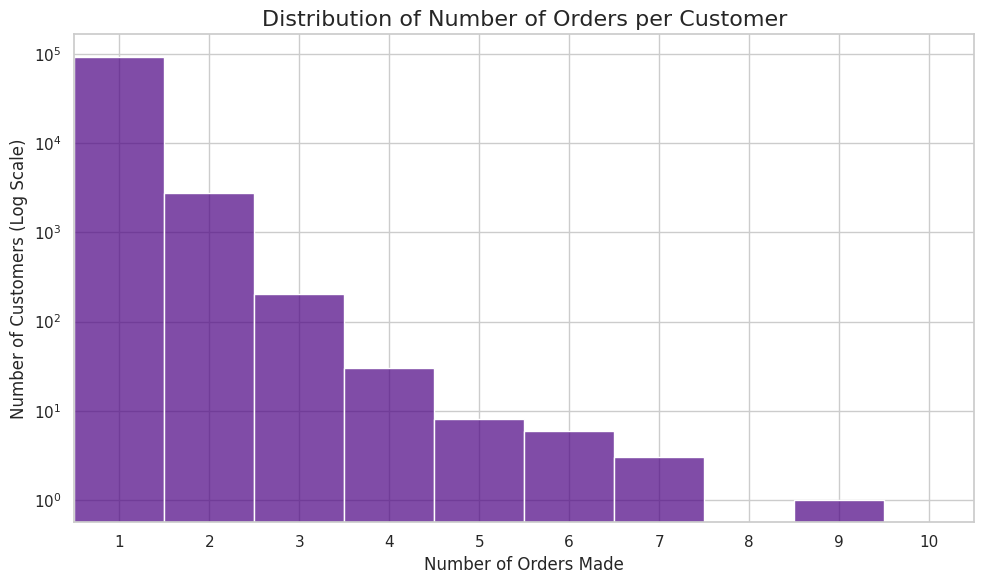

In [69]:
# Count the number of unique orders per unique customer
customer_orders = df_clean.groupby('customer_unique_id')['order_id'].nunique().reset_index(name='order_count')

plt.figure(figsize=(10, 6))
# Set discrete=True because order counts are integer values
ax5 = sns.histplot(data=customer_orders, x='order_count', discrete=True, color='indigo', alpha=0.7)

plt.title('Distribution of Number of Orders per Customer', fontsize=16)
plt.xlabel('Number of Orders Made', fontsize=12)
plt.ylabel('Number of Customers (Log Scale)', fontsize=12)

# Apply a logarithmic scale to the y-axis to make the tail visible
plt.yscale('log')

# Restrict the x-axis to focus on the meaningful range (e.g., 1 to 10 orders)
# Very few outliers have more than 10 orders
plt.xlim(0.5, 10.5) 

# Ensure x-axis ticks are whole numbers
plt.xticks(range(1, 11))
plt.tight_layout()
plt.show()

## Revenue Over Time

/tmp/ipykernel_48/2141743778.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_clean['order_purchase_timestamp'] = pd.to_datetime(df_clean['order_purchase_timestamp'])
/tmp/ipykernel_48/2141743778.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_clean['order_month'] = df_clean['order_purchase_timestamp'].dt.to_period('M').astype(str)


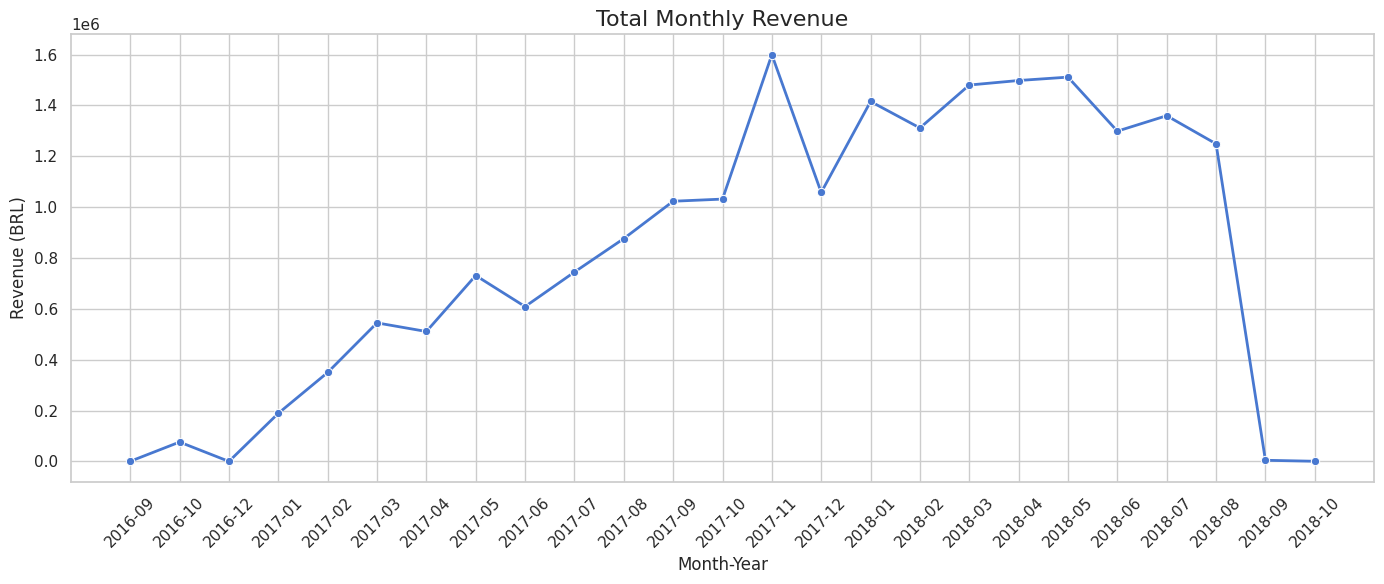

In [25]:
# Extract the Year-Month
df_clean['order_month'] = df_clean['order_purchase_timestamp'].dt.to_period('M').astype(str)

# Group by month to get total revenue
monthly_revenue = df_clean.groupby('order_month')['payment_value'].sum().reset_index()

# Plot Monthly Revenue
plt.figure(figsize=(14, 6))
sns.lineplot(data=monthly_revenue, x='order_month', y='payment_value', marker='o', linewidth=2)
plt.title('Total Monthly Revenue', fontsize=16)
plt.xlabel('Month-Year', fontsize=12)
plt.ylabel('Revenue (BRL)', fontsize=12)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Top Performing Product Categories

/tmp/ipykernel_48/3004676196.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax1 = sns.barplot(data=top_categories, x='payment_value', y='product_category_name_english', palette="viridis")


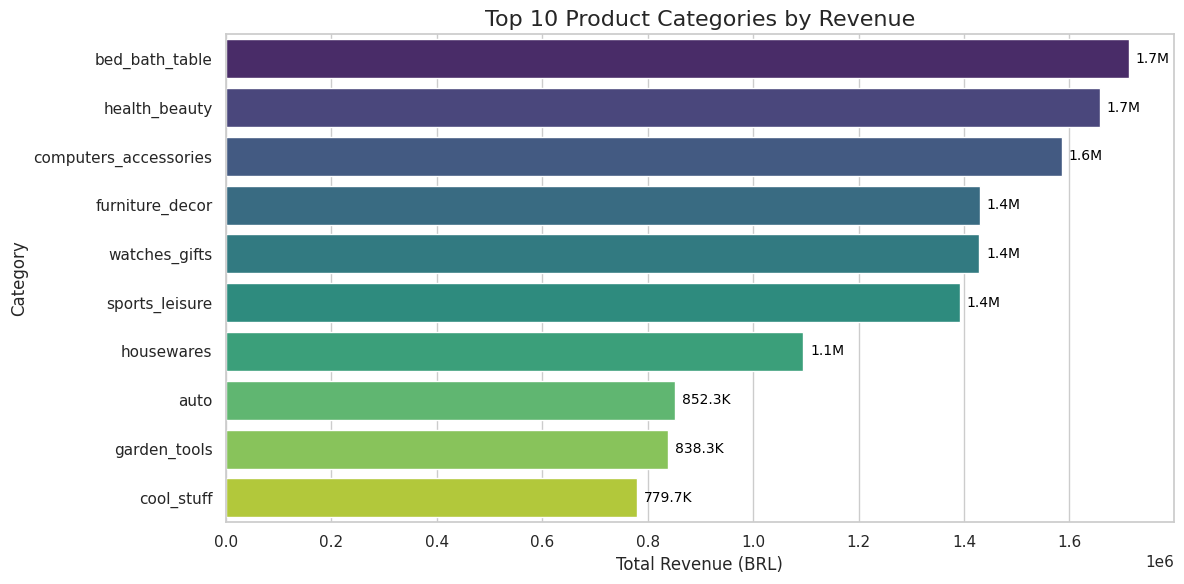

In [41]:
# Calculate total revenue per category
top_categories = (
    df_clean.groupby('product_category_name_english')['payment_value']
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

plt.figure(figsize=(12, 6))
ax1 = sns.barplot(data=top_categories, x='payment_value', y='product_category_name_english', palette="viridis", hue='product_category_name_english')
plt.title('Top 10 Product Categories by Revenue', fontsize=16)
plt.xlabel('Total Revenue (BRL)', fontsize=12)
plt.ylabel('Category', fontsize=12)

# Add custom formatted data labels to the ends of the horizontal bars
for container in ax1.containers:
    labels = [format_k_m(val) for val in container.datavalues]
    ax1.bar_label(container, labels=labels, padding=5, fontsize=10, color='black')

plt.tight_layout()
plt.show()

## Customer Geography (Orders by State)

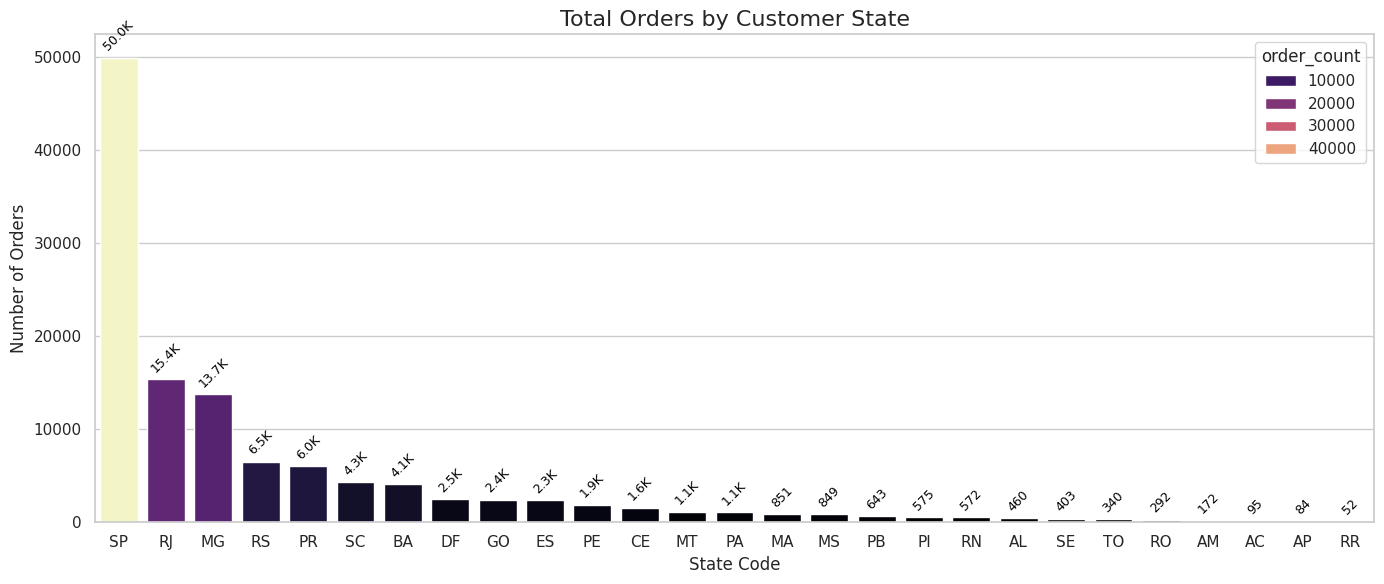

In [43]:
# Count unique orders per state
state_orders = df_clean['customer_state'].value_counts().reset_index()
state_orders.columns = ['customer_state', 'order_count']

plt.figure(figsize=(14, 6))
ax2 = sns.barplot(data=state_orders, x='customer_state', y='order_count', palette="magma", hue='order_count')
plt.title('Total Orders by Customer State', fontsize=16)
plt.xlabel('State Code', fontsize=12)
plt.ylabel('Number of Orders', fontsize=12)

# Add custom formatted data labels above the vertical bars
for container in ax2.containers:
    labels = [format_k_m(val) for val in container.datavalues]
    ax2.bar_label(container, labels=labels, padding=3, fontsize=9, color='black', rotation=45)

plt.tight_layout()
plt.show()

## Payment Method Preferences


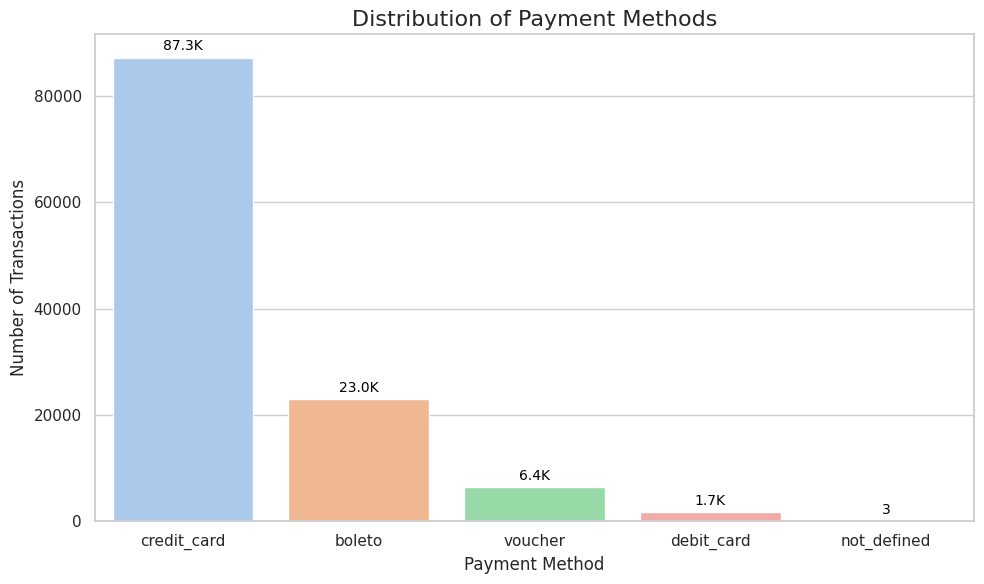

In [48]:
plt.figure(figsize=(10, 6))
payment_counts = df_clean['payment_type'].value_counts().reset_index()
payment_counts.columns = ['payment_type', 'count']

# Create a bar chart for payment methods
ax3 = sns.barplot(data=payment_counts, x='payment_type', y='count', palette="pastel", hue='payment_type')
plt.title('Distribution of Payment Methods', fontsize=16)
plt.xlabel('Payment Method', fontsize=12)
plt.ylabel('Number of Transactions', fontsize=12)

# Add custom formatted data labels using the format_k_m function
for container in ax3.containers:
    labels = [format_k_m(val) for val in container.datavalues]
    ax3.bar_label(container, labels=labels, padding=3, fontsize=10, color='black')

plt.tight_layout()
plt.show()

# RFM Segmentation

In [55]:
# 1. Establish a reference date (1 day after the most recent purchase in the dataset)
reference_date = df_clean['order_purchase_timestamp'].max() + dt.timedelta(days=1)

# 2. Calculate Recency, Frequency, and Monetary values per unique customer
rfm = df_clean.groupby('customer_unique_id').agg(
    Recency=('order_purchase_timestamp', lambda x: (reference_date - x.max()).days),
    Frequency=('order_id', 'nunique'),
    Monetary=('payment_value', 'sum')
).reset_index()

# 3. Assign RFM scores from 1 to 4 using quartiles
# Recency: Lower days since last purchase is better (4 is best)
rfm['R_Score'] = pd.qcut(rfm['Recency'], q=4, labels=[4, 3, 2, 1])

# Frequency: Higher number of orders is better. 
# (Using rank(method='first') because the vast majority of Olist customers only have 1 order, creating duplicate edges)
rfm['F_Score'] = pd.qcut(rfm['Frequency'].rank(method='first'), q=4, labels=[1, 2, 3, 4])

# Monetary: Higher spend is better (4 is best)
rfm['M_Score'] = pd.qcut(rfm['Monetary'], q=4, labels=[1, 2, 3, 4])

# 4. Combine individual scores into an RFM Segment string and a composite Score
rfm['RFM_Segment'] = rfm['R_Score'].astype(str) + rfm['F_Score'].astype(str) + rfm['M_Score'].astype(str)
rfm['RFM_Score'] = rfm[['R_Score', 'F_Score', 'M_Score']].astype(int).sum(axis=1)

# 5. Define high-level customer tiers based on the composite score (range: 3 to 12)
def segment_customer(score):
    if score >= 10:
        return 'Champions'
    elif score >= 8:
        return 'Loyal Customers'
    elif score >= 6:
        return 'At Risk'
    else:
        return 'Lost/Low Value'

rfm['Customer_Tier'] = rfm['RFM_Score'].apply(segment_customer)

# Preview the segmented data
print(rfm[['customer_unique_id', 'Recency', 'Frequency', 'Monetary', 'RFM_Segment', 'RFM_Score', 'Customer_Tier']].head())

                 customer_unique_id  Recency  Frequency  Monetary RFM_Segment  \
0  0000366f3b9a7992bf8c76cfdf3221e2      161          1    141.90         413   
1  0000b849f77a49e4a4ce2b2a4ca5be3f      164          1     27.19         411   
2  0000f46a3911fa3c0805444483337064      586          1     86.22         112   
3  0000f6ccb0745a6a4b88665a16c9f078      370          1     43.62         211   
4  0004aac84e0df4da2b147fca70cf8255      337          1    196.89         213   

   RFM_Score    Customer_Tier  
0          8  Loyal Customers  
1          6          At Risk  
2          4   Lost/Low Value  
3          4   Lost/Low Value  
4          6          At Risk  


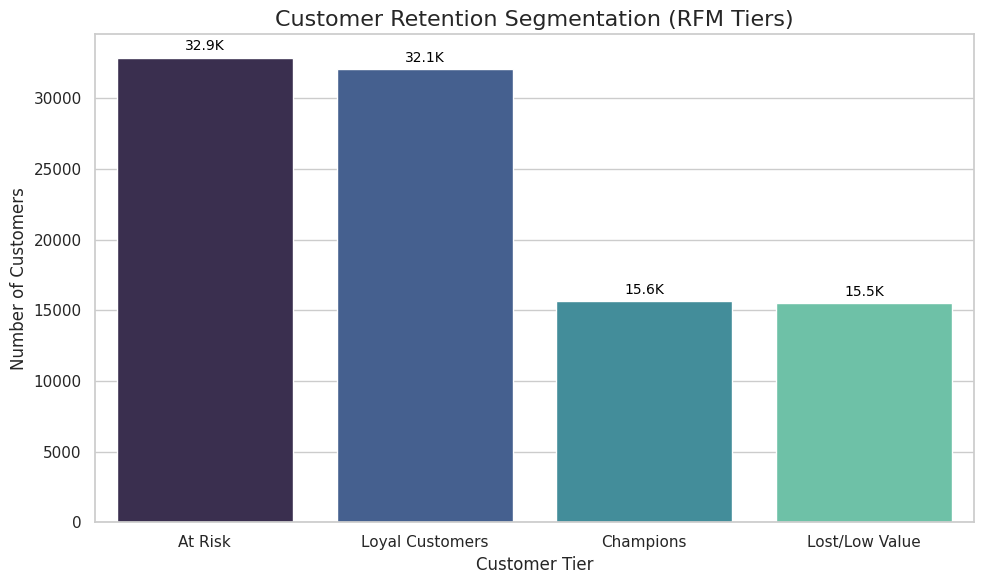

In [57]:
# Count the number of customers in each tier
tier_counts = rfm['Customer_Tier'].value_counts().reset_index()
tier_counts.columns = ['Customer_Tier', 'Count']

plt.figure(figsize=(10, 6))
ax = sns.barplot(data=tier_counts, x='Customer_Tier', y='Count', palette='mako', hue='Customer_Tier')
plt.title('Customer Retention Segmentation (RFM Tiers)', fontsize=16)
plt.xlabel('Customer Tier', fontsize=12)
plt.ylabel('Number of Customers', fontsize=12)

# Add custom formatted data labels using the previously defined format_k_m function
for container in ax.containers:
    labels = [format_k_m(val) for val in container.datavalues]
    ax.bar_label(container, labels=labels, padding=3, fontsize=10, color='black')

plt.tight_layout()
plt.show()

# Delivery Performance

In [58]:
# 1. Convert all relevant date columns to datetime objects
date_cols = ['order_purchase_timestamp', 'order_delivered_customer_date', 'order_estimated_delivery_date']
for col in date_cols:
    df_clean[col] = pd.to_datetime(df_clean[col])

# 2. Filter for delivered orders only to prevent errors from missing delivery dates
df_delivered = df_clean[df_clean['order_status'] == 'delivered'].copy()

# 3. Calculate delivery metrics
# Actual time taken from purchase to delivery (in days)
df_delivered['delivery_time_days'] = (df_delivered['order_delivered_customer_date'] - df_delivered['order_purchase_timestamp']).dt.days

# Difference between estimated and actual delivery (negative value means it was late)
df_delivered['delivery_gap_days'] = (df_delivered['order_estimated_delivery_date'] - df_delivered['order_delivered_customer_date']).dt.days

# Create a binary flag for late deliveries
df_delivered['is_late'] = df_delivered['delivery_gap_days'] < 0

# Preview the new metrics
print(df_delivered[['customer_state', 'delivery_time_days', 'delivery_gap_days', 'is_late']].head())

  customer_state  delivery_time_days  delivery_gap_days  is_late
0             SP                 8.0                7.0    False
1             SP                 8.0                7.0    False
2             SP                 8.0                7.0    False
3             BA                13.0                5.0    False
4             GO                 9.0               17.0    False


/tmp/ipykernel_48/4239054180.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_clean[col] = pd.to_datetime(df_clean[col])
/tmp/ipykernel_48/4239054180.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_clean[col] = pd.to_datetime(df_clean[col])
/tmp/ipykernel_48/4239054180.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-doc

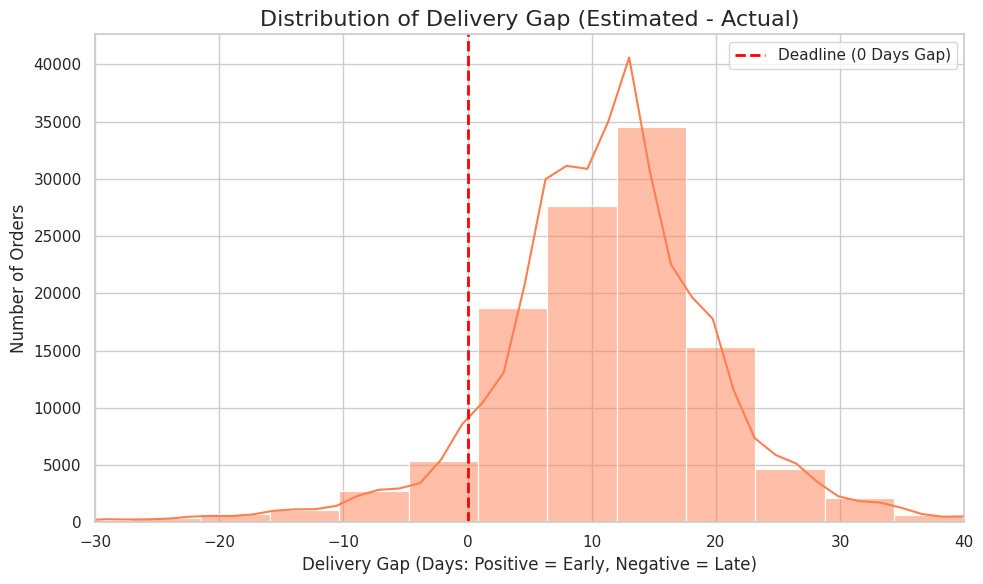

/tmp/ipykernel_48/3028566975.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax4 = sns.barplot(data=state_delivery, x='customer_state', y='late_percentage', palette='Reds_r')


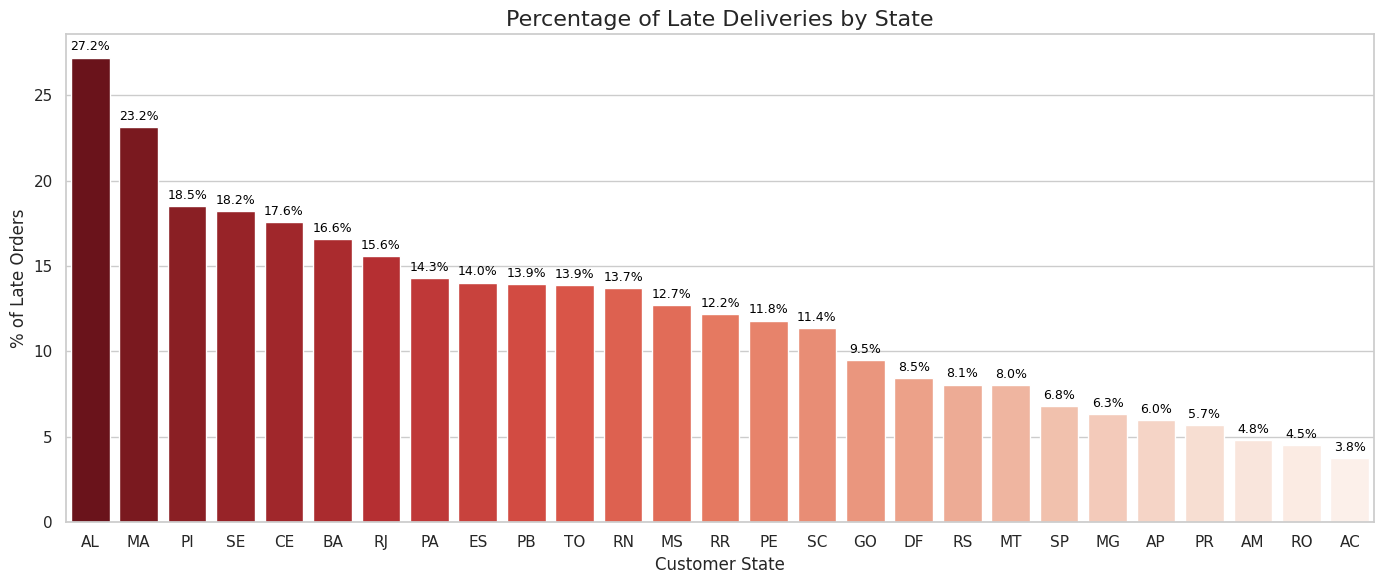

In [61]:
# Chart 1: Distribution of Delivery Gap (Estimated vs Actual)
plt.figure(figsize=(10, 6))
# A positive gap means the order arrived early; a negative gap means it was late
sns.histplot(data=df_delivered, x='delivery_gap_days', bins=60, kde=True, color='coral')
# Add a vertical dashed line at 0 to clearly mark the threshold between early and late
plt.axvline(x=0, color='red', linestyle='--', linewidth=2, label='Deadline (0 Days Gap)')
plt.title('Distribution of Delivery Gap (Estimated - Actual)', fontsize=16)
plt.xlabel('Delivery Gap (Days: Positive = Early, Negative = Late)', fontsize=12)
plt.ylabel('Number of Orders', fontsize=12)
plt.xlim(-30, 40) # Cap the x-axis to focus on the main distribution and exclude extreme outliers
plt.legend()
plt.tight_layout()
plt.show()

# Chart 2: Late Delivery Percentage by State with Data Labels
plt.figure(figsize=(14, 6))
ax4 = sns.barplot(data=state_delivery, x='customer_state', y='late_percentage', palette='Reds_r')
plt.title('Percentage of Late Deliveries by State', fontsize=16)
plt.xlabel('Customer State', fontsize=12)
plt.ylabel('% of Late Orders', fontsize=12)

# Add custom formatted data labels for percentages
for container in ax4.containers:
    # Format the labels to 1 decimal place and append a % sign
    labels = [f'{val:.1f}%' for val in container.datavalues]
    ax4.bar_label(container, labels=labels, padding=3, fontsize=9, color='black')

plt.tight_layout()
plt.show()

# Customer Retention

/tmp/ipykernel_48/751478809.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_clean['order_month'] = df_clean['order_purchase_timestamp'].dt.to_period('M')
/tmp/ipykernel_48/751478809.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_clean['cohort_month'] = df_clean.groupby('customer_unique_id')['order_month'].transform('min')
/tmp/ipykernel_48/751478809.py:20: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = valu

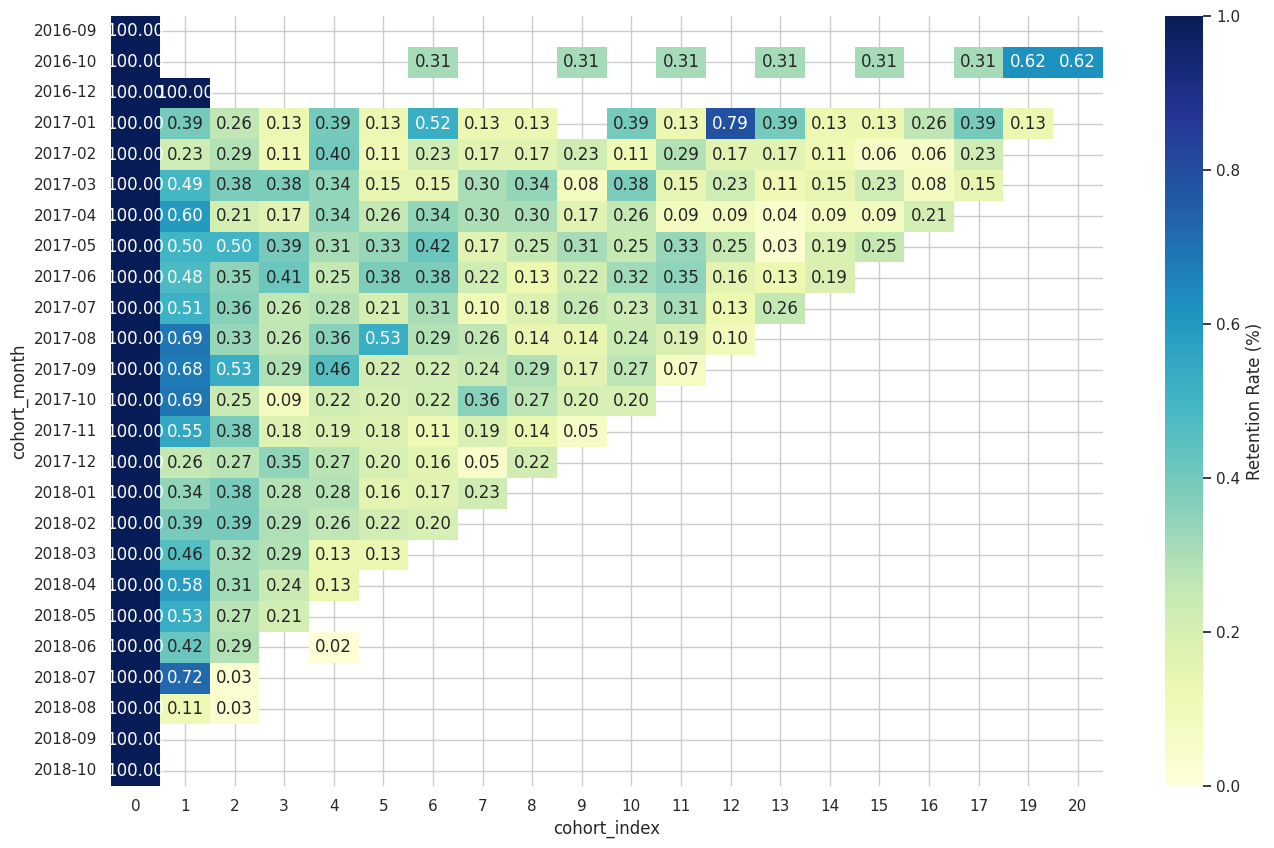

In [66]:
# 1. Create a Year-Month column for the purchase date
df_clean['order_month'] = df_clean['order_purchase_timestamp'].dt.to_period('M')

# 2. Find the first purchase month (Cohort Month) for each unique customer
df_clean['cohort_month'] = df_clean.groupby('customer_unique_id')['order_month'].transform('min')

# 3. Calculate the number of months between the current purchase and the initial cohort month
def get_date_int(df, column):
    year = df[column].dt.year
    month = df[column].dt.month
    return year, month

purchase_year, purchase_month = get_date_int(df_clean, 'order_month')
cohort_year, cohort_month_val = get_date_int(df_clean, 'cohort_month')

years_diff = purchase_year - cohort_year
months_diff = purchase_month - cohort_month_val

# cohort_index represents the number of months since the first purchase (0 = first month)
df_clean['cohort_index'] = years_diff * 12 + months_diff

# 4. Count active unique customers per cohort per month
cohort_data = df_clean.groupby(['cohort_month', 'cohort_index'])['customer_unique_id'].nunique().reset_index()

# 5. Create the retention matrix (pivot table)
cohort_counts = cohort_data.pivot(index='cohort_month', columns='cohort_index', values='customer_unique_id')

# 6. Calculate retention rate percentages
cohort_sizes = cohort_counts.iloc[:, 0] # Month 0 is the starting size of the cohort
retention = cohort_counts.divide(cohort_sizes, axis=0) * 100

# 7. Visualize the retention matrix using a heatmap
plt.figure(figsize=(16, 10))

# We cap vmax at 1.0 (1%) because Olist repeat purchase rates are extremely low. 
# Without this, the 100% column washes out all color variance in the rest of the chart.
ax = sns.heatmap(
    retention, 
    annot=True, 
    fmt='.2f', 
    cmap='YlGnBu', 
    vmin=0.0, 
    vmax=1.0, 
    cbar_kws={'label': 'Retention Rate (%)'}
)

# Customer Satisfaction (Reviews)

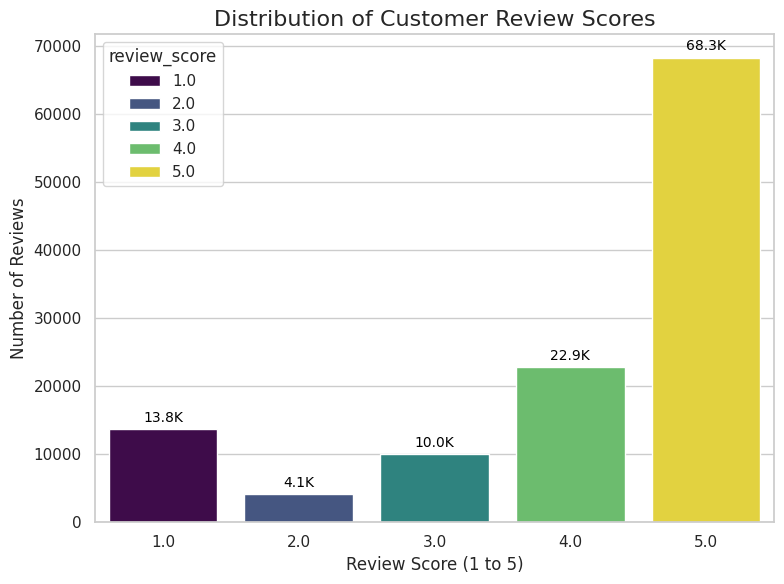

In [75]:
df_delivered = df_delivered.merge(
    order_reviews[['order_id', 'review_score']], 
    on='order_id', 
    how='left'
)

# Drop any orders that did not receive a review
df_reviews = df_delivered.dropna(subset=['review_score']).copy()

# Plot the overall distribution of review scores
plt.figure(figsize=(8, 6))
ax6 = sns.countplot(data=df_reviews, x='review_score', palette='viridis', hue='review_score')
plt.title('Distribution of Customer Review Scores', fontsize=16)
plt.xlabel('Review Score (1 to 5)', fontsize=12)
plt.ylabel('Number of Reviews', fontsize=12)

# Add data labels
for container in ax6.containers:
    labels = [format_k_m(val) for val in container.datavalues]
    ax6.bar_label(container, labels=labels, padding=3, fontsize=10, color='black')

plt.tight_layout()
plt.show()

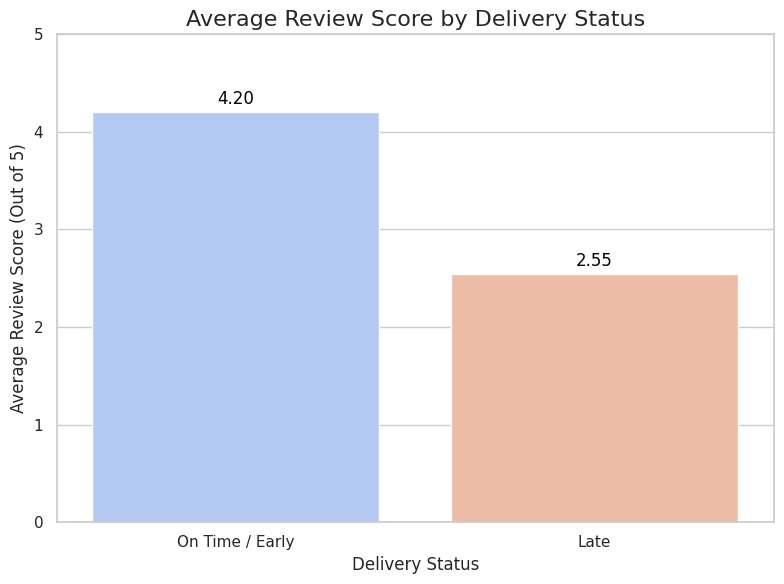

In [76]:
# Calculate the average review score for On-Time vs. Late deliveries
delivery_satisfaction = df_reviews.groupby('is_late')['review_score'].mean().reset_index()
delivery_satisfaction['Delivery Status'] = delivery_satisfaction['is_late'].map({False: 'On Time / Early', True: 'Late'})

plt.figure(figsize=(8, 6))
ax7 = sns.barplot(data=delivery_satisfaction, x='Delivery Status', y='review_score', palette='coolwarm', hue='Delivery Status')
plt.title('Average Review Score by Delivery Status', fontsize=16)
plt.xlabel('Delivery Status', fontsize=12)
plt.ylabel('Average Review Score (Out of 5)', fontsize=12)
plt.ylim(0, 5)

# Add exact average score labels
for container in ax7.containers:
    labels = [f'{val:.2f}' for val in container.datavalues]
    ax7.bar_label(container, labels=labels, padding=3, fontsize=12, color='black')

plt.tight_layout()
plt.show()